# Elo Rating Analysis

This notebook visualizes the dynamically calculated Elo ratings for top players and checks the calibration of the Elo probabilities.

In [8]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.calibration import calibration_curve

plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('tab10')

In [9]:
# Load Elo History
elo_history = pd.read_parquet('../data/processed/elo_history.parquet')
elo_history['tourney_date'] = pd.to_datetime(elo_history['tourney_date'], format='%Y%m%d')
elo_history.sort_values('tourney_date', inplace=True)
elo_history.head()

,match_id,tourney_date,surface,winner_id,loser_id,winner_overall_elo_pre,loser_overall_elo_pre,winner_surface_elo_pre,loser_surface_elo_pre
0,2017-0451_270_104925_105526,2017-01-02,Hard,104925,105526,1500.0,1500.0,1500.0,1500.0
62,2017-M020_276_111442_111200,2017-01-02,Hard,111442,111200,1500.0,1500.0,1500.0,1500.0
61,2017-M020_275_111577_104180,2017-01-02,Hard,111577,104180,1500.0,1500.0,1500.0,1500.0
60,2017-M020_273_106298_104468,2017-01-02,Hard,106298,104468,1500.0,1500.0,1500.0,1500.0
59,2017-M020_272_106378_124014,2017-01-02,Hard,106378,124014,1500.0,1500.0,1500.0,1500.0


In [10]:
# Load players
players = pd.read_csv('../atp_players.csv', names=['player_id', 'first_name', 'last_name', 'hand', 'dob', 'country', 'height', 'wikidata_id'])
players['full_name'] = players['first_name'] + ' ' + players['last_name']
player_map = dict(zip(players['player_id'], players['full_name']))

/var/folders/1n/d73t972s743fmp12n4ly2mtc0000gn/T/ipykernel_21286/2666361907.py:2: DtypeWarning: Columns (0: player_id, 1: dob, 2: height, 3: wikidata_id) have mixed types. Specify dtype option on import or set low_memory=False.
  players = pd.read_csv('../atp_players.csv', names=['player_id', 'first_name', 'last_name', 'hand', 'dob', 'country', 'height', 'wikidata_id'])


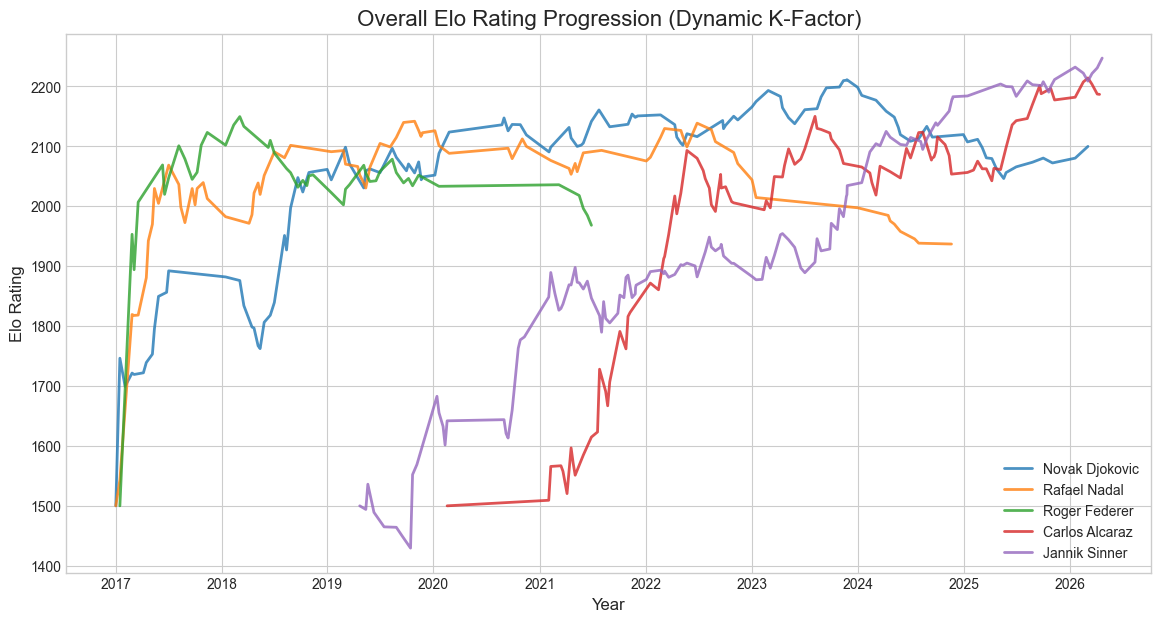

In [11]:
def get_player_elo_timeline(player_id):
    wins = elo_history[elo_history['winner_id'] == player_id][['tourney_date', 'winner_overall_elo_pre']].rename(columns={'winner_overall_elo_pre': 'elo'})
    losses = elo_history[elo_history['loser_id'] == player_id][['tourney_date', 'loser_overall_elo_pre']].rename(columns={'loser_overall_elo_pre': 'elo'})
    timeline = pd.concat([wins, losses]).sort_values('tourney_date')
    # Take the last elo of each tournament to smooth lines
    timeline = timeline.groupby('tourney_date').last().reset_index()
    return timeline

target_players = {
    104925: 'Novak Djokovic',
    104745: 'Rafael Nadal',
    103819: 'Roger Federer',
    207989: 'Carlos Alcaraz',
    206173: 'Jannik Sinner'
}

plt.figure(figsize=(14, 7))
for pid, name in target_players.items():
    timeline = get_player_elo_timeline(pid)
    plt.plot(timeline['tourney_date'], timeline['elo'], label=name, alpha=0.8, linewidth=2)

plt.title('Overall Elo Rating Progression (Dynamic K-Factor)', fontsize=16)
plt.xlabel('Year', fontsize=12)
plt.ylabel('Elo Rating', fontsize=12)
plt.legend()
plt.show()

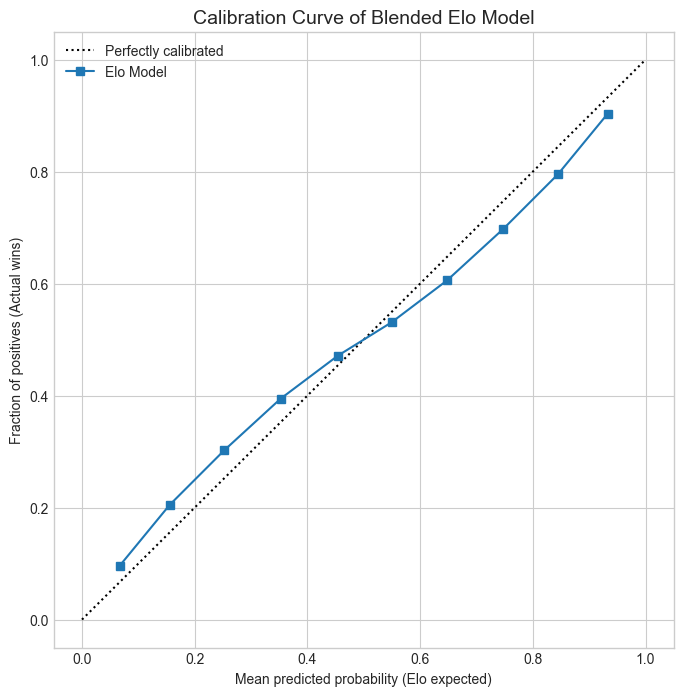

In [7]:
# Load Model Training Rows for Calibration
training_rows = pd.read_parquet('../data/processed/model_training_rows.parquet')

# Filter out NAs in Elo expectation
valid_rows = training_rows.dropna(subset=['elo_expected_a', 'player_a_wins'])

prob_true, prob_pred = calibration_curve(valid_rows['player_a_wins'], valid_rows['elo_expected_a'], n_bins=10)

plt.figure(figsize=(8, 8))
plt.plot([0, 1], [0, 1], "k:", label="Perfectly calibrated")
plt.plot(prob_pred, prob_true, "s-", label="Elo Model")
plt.xlabel("Mean predicted probability (Elo expected)")
plt.ylabel("Fraction of positives (Actual wins)")
plt.title('Calibration Curve of Blended Elo Model', fontsize=14)
plt.legend()
plt.show()